In [ ]:
import numpy as np

In [ ]:
import pandas as pd

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
import tensorflow as tf

In [ ]:
from sklearn.preprocessing import MinMaxScaler

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [ ]:
print(tf.__version__)

2.21.0


In [ ]:
import requests

In [ ]:
url = "https://archive-api.open-meteo.com/v1/archive"

In [ ]:
params = {
    "latitude": 13.0827,
    "longitude": 80.2707,
    "start_date": "2010-01-01",
    "end_date": "2025-12-31",
    "daily": "temperature_2m_mean",
    "timezone": "Asia/Kolkata"
}

In [ ]:
response = requests.get(url, params=params)
response.raise_for_status()
weather_data = response.json()
df = pd.DataFrame({
    "Date": weather_data["daily"]["time"],
    "Temperature": weather_data["daily"]["temperature_2m_mean"]
})
print("Dataset loaded successfully!")
print("Number of rows:", len(df))
print(df.head())

Dataset loaded successfully!
Number of rows: 5844
         Date  Temperature
0  2010-01-01         24.3
1  2010-01-02         24.3
2  2010-01-03         24.1
3  2010-01-04         23.1
4  2010-01-05         22.8


In [ ]:
df["Date"] = pd.to_datetime(df["Date"])
df["Temperature"] = pd.to_numeric(
    df["Temperature"], errors="coerce"
)
df = df.dropna(subset=["Temperature"]).reset_index(drop=True)
print("Dataset loaded successfully!")
print(df.head())
print("Total records:", len(df))

Dataset loaded successfully!
        Date  Temperature
0 2010-01-01         24.3
1 2010-01-02         24.3
2 2010-01-03         24.1
3 2010-01-04         23.1
4 2010-01-05         22.8
Total records: 5844


In [ ]:
print(df.head())

         Date  Temperature
0  2010-01-01         24.3
1  2010-01-02         24.3
2  2010-01-03         24.1
3  2010-01-04         23.1
4  2010-01-05         22.8


In [ ]:
print(df.shape)

(5844, 2)


In [ ]:
print(df.dtypes)

Date            object
Temperature    float64
dtype: object


In [ ]:
print(df.isnull().sum())

Date           0
Temperature    0
dtype: int64


In [ ]:
print(df["Temperature"].describe())

count    5844.000000
mean       28.009993
std         2.420371
min        21.300000
25%        25.900000
50%        28.200000
75%        29.800000
max        35.600000
Name: Temperature, dtype: float64


In [ ]:

df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)
print(df.dtypes)
print(df.head())


Date           datetime64[ns]
Temperature           float64
dtype: object
        Date  Temperature
0 2010-01-01         24.3
1 2010-01-02         24.3
2 2010-01-03         24.1
3 2010-01-04         23.1
4 2010-01-05         22.8


In [ ]:
print(df["Temperature"].isnull().sum())

0


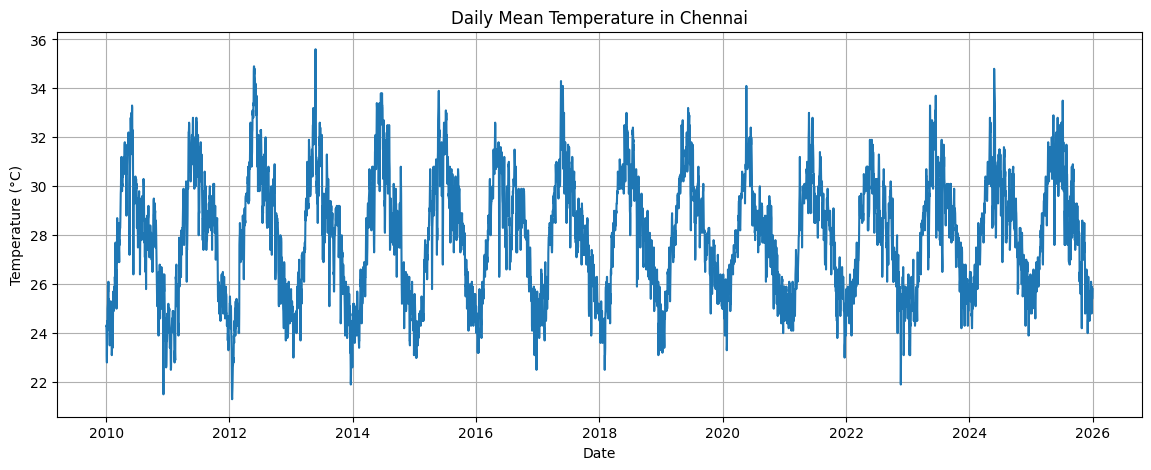

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(df["Date"], df["Temperature"])
plt.title("Daily Mean Temperature in Chennai")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.show()


In [ ]:
temperatures = df["Temperature"].values.reshape(-1, 1)
n = len(temperatures)
train_end = int(n * 0.70)
val_end = int(n * 0.85)
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(temperatures[:train_end])
scaled_temperatures = scaler.transform(temperatures)
print("Training records:", train_end)
print("Validation records:", val_end - train_end)
print("Test records:", n - val_end)

Training records: 4090
Validation records: 877
Test records: 877


In [ ]:

window_size = 7  # Change to 30 to use the previous 30 days
def create_sequences(data, window_size):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i + window_size])
        y.append(data[i + window_size])
    return np.array(X), np.array(y)
X, y = create_sequences(scaled_temperatures, window_size)
print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (5837, 7, 1)
Output shape: (5837, 1)


In [ ]:
X_train = X[:train_end - window_size]
y_train = y[:train_end - window_size]
X_val = X[train_end - window_size:val_end - window_size]
y_val = y[train_end - window_size:val_end - window_size]
X_test = X[val_end - window_size:]
y_test = y[val_end - window_size:]
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (4083, 7, 1)
X_val: (877, 7, 1)
X_test: (877, 7, 1)


In [ ]:
model = Sequential([
    Input(shape=(window_size, 1)),
    SimpleRNN(units=16, activation="tanh"),
    Dense(1)
])
model.summary()
model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_2 (SimpleRNN)        │ (None, 16)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305 (1.19 KB)

 Trainable params: 305 (1.19 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1
)
print("Training completed!")

Epoch 1/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0891 - val_loss: 0.0047
Epoch 2/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0040 - val_loss: 0.0033
Epoch 3/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0030 - val_loss: 0.0030
Epoch 4/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0026 - val_loss: 0.0027
Epoch 5/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0024 - val_loss: 0.0025
Epoch 6/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0023 - val_loss: 0.0024
Epoch 7/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0022 - val_loss: 0.0023
Epoch 8/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0021 - val_loss: 0.0023
Epoch 9/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0021 - val_loss: 0.0023
Epoch 10/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0021 - val_loss: 0.0022
Epoch 11/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0021 - val_loss: 0.0023
Epoch 12/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

In [ ]:
y_pred_scaled = model.predict(X_test, verbose=0)
y_pred = scaler.inverse_transform(y_pred_scaled)
y_actual = scaler.inverse_transform(y_test)
mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
print(f"Test MAE:  {mae:.2f} °C")
print(f"Test RMSE: {rmse:.2f} °C")

Test MAE:  0.53 °C
Test RMSE: 0.70 °C


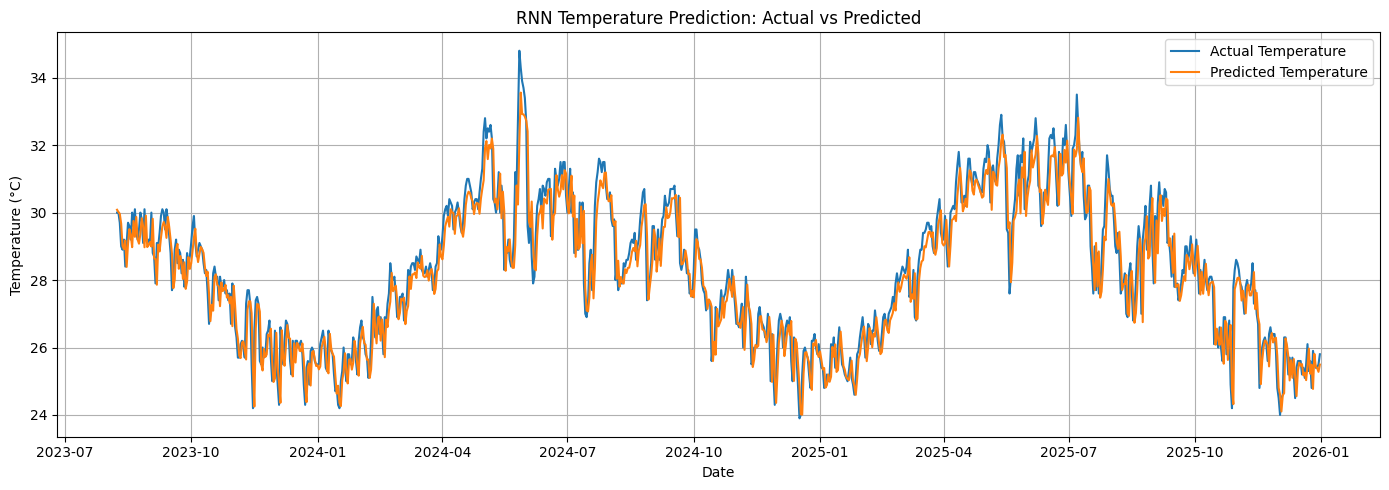

In [ ]:
test_dates = df["Date"].iloc[val_end:].reset_index(drop=True)
plt.figure(figsize=(14, 5))
plt.plot(test_dates, y_actual.flatten(), label="Actual Temperature")
plt.plot(test_dates, y_pred.flatten(), label="Predicted Temperature")
plt.title("RNN Temperature Prediction: Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:

last_days = df["Temperature"].tail(window_size).values.reshape(-1, 1)
last_days_scaled = scaler.transform(last_days)
input_sequence = last_days_scaled.reshape(1, window_size, 1)
next_scaled = model.predict(input_sequence, verbose=0)
next_temperature = scaler.inverse_transform(next_scaled)[0, 0]
next_date = df["Date"].max() + pd.Timedelta(days=1)
print("Input temperatures (°C):")
print(last_days.flatten())
print("\nPrediction date:", next_date.date())
print(f"Predicted next-day temperature: {next_temperature:.2f} °C")

Input temperatures (°C):
[24.8 25.9 25.6 25.4 25.4 25.5 25.8]

Prediction date: 2026-01-01
Predicted next-day temperature: 25.61 °C


In [ ]:
model.save("temperature_rnn.keras")
print("Model saved successfully!")

Model saved successfully!
